# Validation of mean velocities and time series (AOI + test polygons)

Compares four InSAR point datasets of the same ascending track over Vienna:

| Dataset | Role | Velocity used (2022-01-01 – 2024-12-31) |
|---|---|---|
| **Augmenterra** | reference | `VEL_20220101_20241231` |
| **EGMS** | reference | `VEL_20220101_20241231` |
| **COMPASS-Dolphin** | own COMPASS-Dolphin processing | `velocity_dolphin` |
| **ISCE2-Dolphin-MintPy** | own ISCE2-Dolphin-MintPy processing (`S1_ASC_073_IW1-IW2_VV_20220101_20241228_vienna`) | `velocity_mintpy` |

**Workflow**
1. File overview from the parquet metadata only (no data read).
2. Load the points inside the project AOI: only coordinates, velocity and coherence.
3. Compare the datasets over the whole AOI: tables, histograms, gridded maps.
4. Compare velocities inside test polygons.
5. Compare the deformation time series inside one polygon, after re-referencing them to a common date.

**Conventions**: velocities in mm/yr, displacements in mm, both in line of sight (LOS).
Negative = movement away from the satellite (e.g. subsidence).

**Code**: readers, metrics and helpers come from the package `aducat_val` (`src/aducat_val/`).
Conventions (sign, units, CRS, reference): `docs/conventions.md`.

**Efficiency**: the large files are read one row group at a time and only the columns that are needed.
The loader remembers where each point sits in the file (row group + row), so the time series of a polygon
are read later from only the row groups that contain its points.

In [1]:
import sys
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm, Normalize

try:
    import aducat_val
except ImportError:  # package not installed with `pip install -e .`: use src/ of this repo (see README.md)
    repo_root = next(p for p in Path.cwd().resolve().parents if (p / "src" / "aducat_val").is_dir())
    sys.path.insert(0, str(repo_root / "src"))

from aducat_val import metrics, readers, spatial
from aducat_val import timeseries as tsa
from aducat_val.config import METRIC_CRS, VELOCITY_CMAP
from aducat_val.display import plot_ts_band, show, style_map

## Configuration

Set the paths at the top of the next cell to where the data is on your machine.
`DATASETS` maps each dataset name to its file and the options of its source function in `aducat_val/readers.py`
(velocity column, ...). Every later cell loops over the datasets, so one can be added, removed
or switched (another file or velocity column) here only.

In [2]:
# ---- Paths: set them to where the data is on your machine ----
DATA_DIR = Path("/home/lukas/projects/ADUCAT/data")
AOI_FILE = DATA_DIR / "AOI/Projektgebiet_ADUCAT-AOI.gpkg"
POLYGON_FILE = DATA_DIR / "AOI/polygon_test.gpkg"

# name -> file and options of the source function in aducat_val/readers.py (velocity column, ...)
DATASETS = {
    "Augmenterra": dict(file=DATA_DIR / "Augmenterra/processed/VIENNA_TUNNELLING_velocity_ASC.parquet",
                        velocity="VEL_20220101_20241231"),
    "EGMS": dict(file=DATA_DIR / "EGMS/vienna/processed/EGMS_073_2020_2024.parquet",
                 velocity="VEL_20220101_20241231"),
    "COMPASS-Dolphin": dict(file=DATA_DIR / "final_outputs/COMPASS-DOLPHIN/dolphin_points_2020-2024.parquet"),
    "ISCE2-Dolphin-MintPy": dict(
        file=DATA_DIR / "final_outputs/isce2-dolphin-mintpy/S1_ASC_073_IW1-IW2_VV_20220101_20241228_vienna.parquet"),
}
SOURCES = readers.sources(DATASETS)

# own processings (validated against the references and against each other)
OWN = [name for name, src in SOURCES.items() if src.kind == "pipeline"]
# differences "own − other": every own dataset vs. every reference, plus the own datasets against each other
DIFF_PAIRS = [(own, other) for i, own in enumerate(OWN) for other in SOURCES if other not in OWN[i:]]

# Coherence threshold per dataset: points with a lower coherence (or no coherence) are dropped right after
# loading and are then missing in all following steps. 0 = keep all points.
# The providers compute coherence differently, so a threshold of one dataset does not mean the same in another.
MIN_COHERENCE = {
    "Augmenterra": 0.0,
    "EGMS": 0.0,
    "COMPASS-Dolphin": 0.9,
    "ISCE2-Dolphin-MintPy": 0.9,
}

# Analysis settings (METRIC_CRS from aducat_val.config: used for areas, distances and the gridded maps)
VEL_LIMIT = 20                     # colour and histogram range: -VEL_LIMIT ... +VEL_LIMIT mm/yr
CMAP = VELOCITY_CMAP               # red = negative (away from satellite), blue = positive
MAP_CELL_SIZE_M = 50               # cell size of the gridded overview maps
TS_START, TS_END = pd.Timestamp("2019-01-01"), pd.Timestamp("2026-04-30")   # time-series window
MAX_TS_LINES = 300                 # max. individual time series drawn per dataset (random sample)

## 1. File overview (metadata only)

Read from the parquet footer only, no point data is loaded.

In [3]:
display(pd.DataFrame({name: readers.file_overview(src) for name, src in SOURCES.items()}))

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
file,VIENNA_TUNNELLING_velocity_ASC.parquet,EGMS_073_2020_2024.parquet,dolphin_points_2020-2024.parquet,S1_ASC_073_IW1-IW2_VV_20220101_20241228_vienna...
size [GB],1.44,0.40,4.62,3.60
points,"2,924,926","1,446,002","6,396,038","7,926,405"
row groups,150,17,30,12
geometry CRS,EPSG:4326,EPSG:4326,EPSG:32633,OGC:CRS84
time steps,343,209,92,92
first date,2019-01-05,2020-01-06,2022-01-01,2022-01-01
last date,2026-04-28,2024-12-28,2024-12-28,2024-12-28
median spacing [days],6.0,6.0,12.0,12.0
velocity column,VEL_20220101_20241231,VEL_20220101_20241231,velocity_dolphin,velocity_mintpy


Attribute columns of each dataset (time-series columns and their `_std` columns left out):

In [4]:
display(pd.DataFrame({name: pd.Series(readers.attribute_columns(src)) for name, src in SOURCES.items()}).fillna(""))

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
0,CODE,pid,point_id,point_id
1,HEIGHT,cluster_label,lon,row
2,H_STDEV,mp_type,lat,col
3,VEL,easting,height,lon
4,V_STDEV,northing,local_incidence_angle,lat
5,ACC,height_ortho,los_east,height
6,A_STDEV,height_ellipse,los_north,incidence_angle
7,SEASON_AMP,line,los_up,azimuth_angle
8,S_AMP_STD,pixel,temporal_coherence,los_east
9,SEASON_PHS,rmse_ts,similarity,los_north


## 2. Load the points inside the AOI

`readers.read_points` reads, per row group, only the coordinates plus the velocity and coherence columns,
and keeps the points inside the polygon. Every dataset comes back with the same core columns
(`lon`, `lat`, `x`, `y`, `velocity`, `coherence`), so all datasets are handled with the same code afterwards.

Columns `rg` and `row` store where each point sits in the file (used later by `readers.read_timeseries`).
`x` / `y` are metric coordinates (`METRIC_CRS`) for areas and maps.

The coherence thresholds from `MIN_COHERENCE` are applied right after loading. The second table below shows which
share of the points in the AOI would remain at other thresholds, to help choose them.

In [5]:
aoi_polygon, aoi_metric = spatial.read_aoi(AOI_FILE)
aoi_area_km2 = aoi_metric.area.sum() / 1e6
print(f"AOI area: {aoi_area_km2:.1f} km²   bounds (lon/lat): {np.round(aoi_polygon.bounds, 4)}")

AOI area: 484.8 km²   bounds (lon/lat): [16.181  48.1174 16.5876 48.3243]


ERROR 1: PROJ: proj_create_from_database: Open of /home/lukas/miniforge3/envs/geo_env/share/proj failed


In [6]:
points = {}
loading = {}
threshold_shares = {}

for name, src in SOURCES.items():
    t0 = time.perf_counter()
    pts = readers.read_points(src, aoi_polygon)
    min_coh = MIN_COHERENCE.get(name, 0.0)
    n_aoi_all = len(pts)

    threshold_shares[name] = metrics.coherence_shares(pts["coherence"])
    if min_coh > 0:
        pts = pts[pts["coherence"] >= min_coh].reset_index(drop=True)
    points[name] = pts

    loading[name] = {
        "coherence threshold": min_coh,
        "points in AOI": n_aoi_all,
        "points kept": len(pts),
        "kept [%]": 100 * len(pts) / n_aoi_all if n_aoi_all else np.nan,
        "loading time [s]": time.perf_counter() - t0,
    }

show(pd.DataFrame(loading), decimals=2, int_labels=("points in AOI", "points kept"))
print("Share of points in the AOI [%] at or above a coherence threshold (before filtering):")
show(pd.DataFrame(threshold_shares), decimals=1)

# short description of the thresholds for the figure titles
COH_INFO = "coherence ≥ " + ", ".join(f"{MIN_COHERENCE.get(name, 0.0)} ({name})" for name in points)

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
coherence threshold,0.00,0.00,0.90,0.90
points in AOI,"2,918,003","1,252,938","4,588,399","5,203,546"
points kept,"2,918,003","1,252,938","2,124,327","5,110,284"
kept [%],100.00,100.00,46.30,98.21
loading time [s],3.32,1.09,2.20,2.29


Share of points in the AOI [%] at or above a coherence threshold (before filtering):


,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
≥ 0.3,91.7,99.9,99.9,100.0
≥ 0.5,60.4,99.4,73.7,100.0
≥ 0.6,46.8,95.9,62.6,100.0
≥ 0.7,32.7,79.2,57.6,100.0
≥ 0.8,21.8,56.5,52.9,99.4
≥ 0.9,8.8,19.9,46.3,98.2


## 3. Comparison over the whole AOI

### 3.1 Number of points and coverage

The datasets do not cover the same part of the AOI. The *covered area* counts the 100 m × 100 m cells
that contain at least one point, so the point density refers to the area that actually has data.

In [7]:
coverage = {}
for name, pts in points.items():
    area = spatial.covered_area_km2(pts["x"], pts["y"], cell=100)
    coverage[name] = {
        "points": len(pts),
        "covered area [km²]": area,
        "AOI covered [%]": 100 * area / aoi_area_km2,
        "points per km² (covered area)": len(pts) / area if area else np.nan,
    }
show(pd.DataFrame(coverage), decimals=1)

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
points,"2,918,003","1,252,938","2,124,327","5,110,284"
covered area [km²],390.9,288.9,285.5,330.4
AOI covered [%],80.6,59.6,58.9,68.2
points per km² (covered area),"7,465.6","4,336.5","7,441.0","15,466.0"


### 3.2 Velocity statistics

`metrics.velocity_summary`: P2 … P98 are percentiles; IQR = P75 − P25 and NMAD are robust measures of the spread.
The last rows give the share of points that are stable or move faster than ±5 mm/yr.

In [8]:
aoi_velocity_stats = pd.DataFrame({name: metrics.velocity_summary(pts["velocity"]) for name, pts in points.items()})
show(aoi_velocity_stats)

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
points,"2,918,003","1,252,938","2,124,327","5,110,284"
mean,-0.34,-0.33,0.83,0.02
std,1.75,1.27,0.92,1.52
min,-25.30,-93.10,-42.85,-62.82
P2,-5.00,-3.00,-1.19,-3.58
P25,-1.00,-0.80,0.48,-0.40
median,-0.20,-0.30,0.91,0.14
P75,0.50,0.30,1.29,0.69
P98,3.10,1.90,2.23,2.32
max,14.10,29.60,37.53,23.82


### 3.3 Coherence statistics

Each provider computes its coherence differently (and possibly on a different scale),
so compare the distributions within a dataset rather than the values across datasets.
The statistics refer to the points kept after applying `MIN_COHERENCE`.

In [9]:
coherence_stats = pd.DataFrame({
    name: pts["coherence"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).rename({"count": "points"})
    for name, pts in points.items()
})
show(coherence_stats, decimals=3)

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
points,"2,918,003","1,252,938","2,124,327","5,110,284"
mean,0.585,0.800,0.976,0.997
std,0.214,0.110,0.024,0.012
min,0.150,0.010,0.900,0.900
5%,0.270,0.600,0.921,0.984
25%,0.400,0.720,0.965,1.000
50%,0.570,0.820,0.985,1.000
75%,0.770,0.890,0.994,1.000
95%,0.940,0.940,1.000,1.000
max,1.000,0.980,1.000,1.000


### 3.4 Velocity distributions

Histograms are normalised (density), so the shapes are comparable even though the point counts differ.
Left: the main range. Right: the full range on a log scale to show the tails.

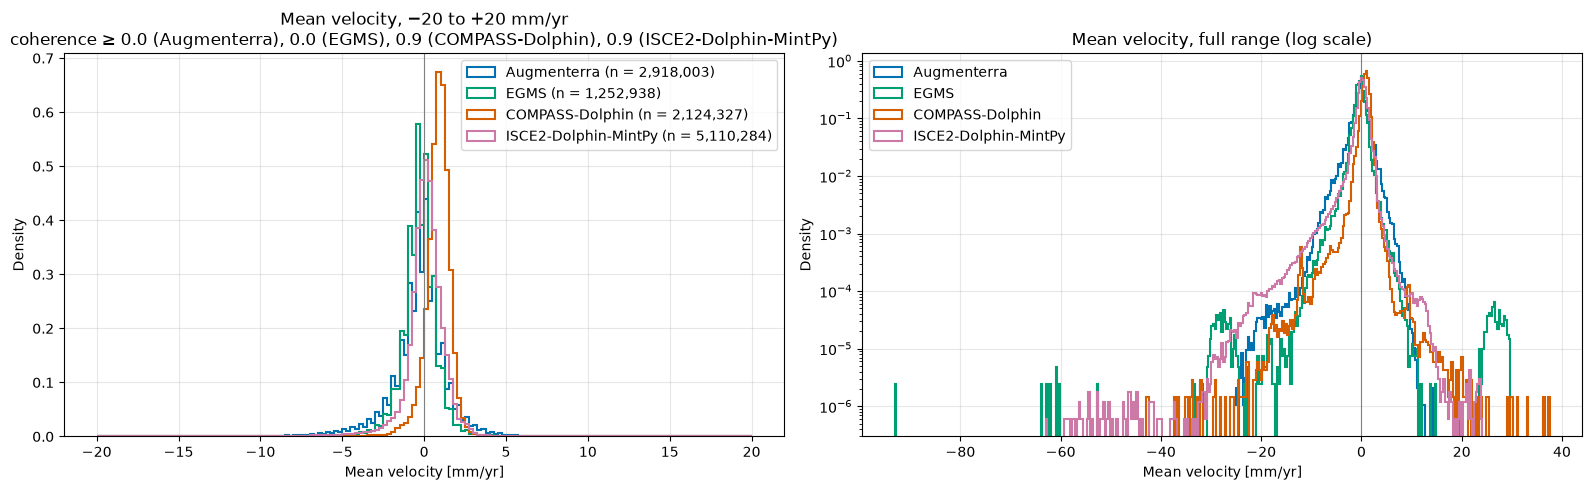

In [10]:
fig, (ax_main, ax_full) = plt.subplots(1, 2, figsize=(16, 5))

all_v = np.concatenate([pts["velocity"].dropna().to_numpy() for pts in points.values()])
full_bins = np.linspace(all_v.min(), all_v.max(), 400)
main_bins = np.linspace(-VEL_LIMIT, VEL_LIMIT, 161)

for name, pts in points.items():
    v = pts["velocity"].dropna()
    style = dict(histtype="step", density=True, lw=1.5, color=SOURCES[name].color)
    ax_main.hist(v, bins=main_bins, label=f"{name} (n = {len(v):,})", **style)
    ax_full.hist(v, bins=full_bins, label=name, **style)

ax_main.set_title(f"Mean velocity, −{VEL_LIMIT} to +{VEL_LIMIT} mm/yr\n{COH_INFO}")
ax_full.set_title("Mean velocity, full range (log scale)")
ax_full.set_yscale("log")
for ax in (ax_main, ax_full):
    ax.axvline(0, color="0.5", lw=0.8)
    ax.set_xlabel("Mean velocity [mm/yr]")
    ax.set_ylabel("Density")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 3.5 Maps

Plotting millions of single points is slow and points overlap, so the points are binned onto a regular
grid (`MAP_CELL_SIZE_M`). Top row: median velocity per cell. Bottom row: number of points per cell.

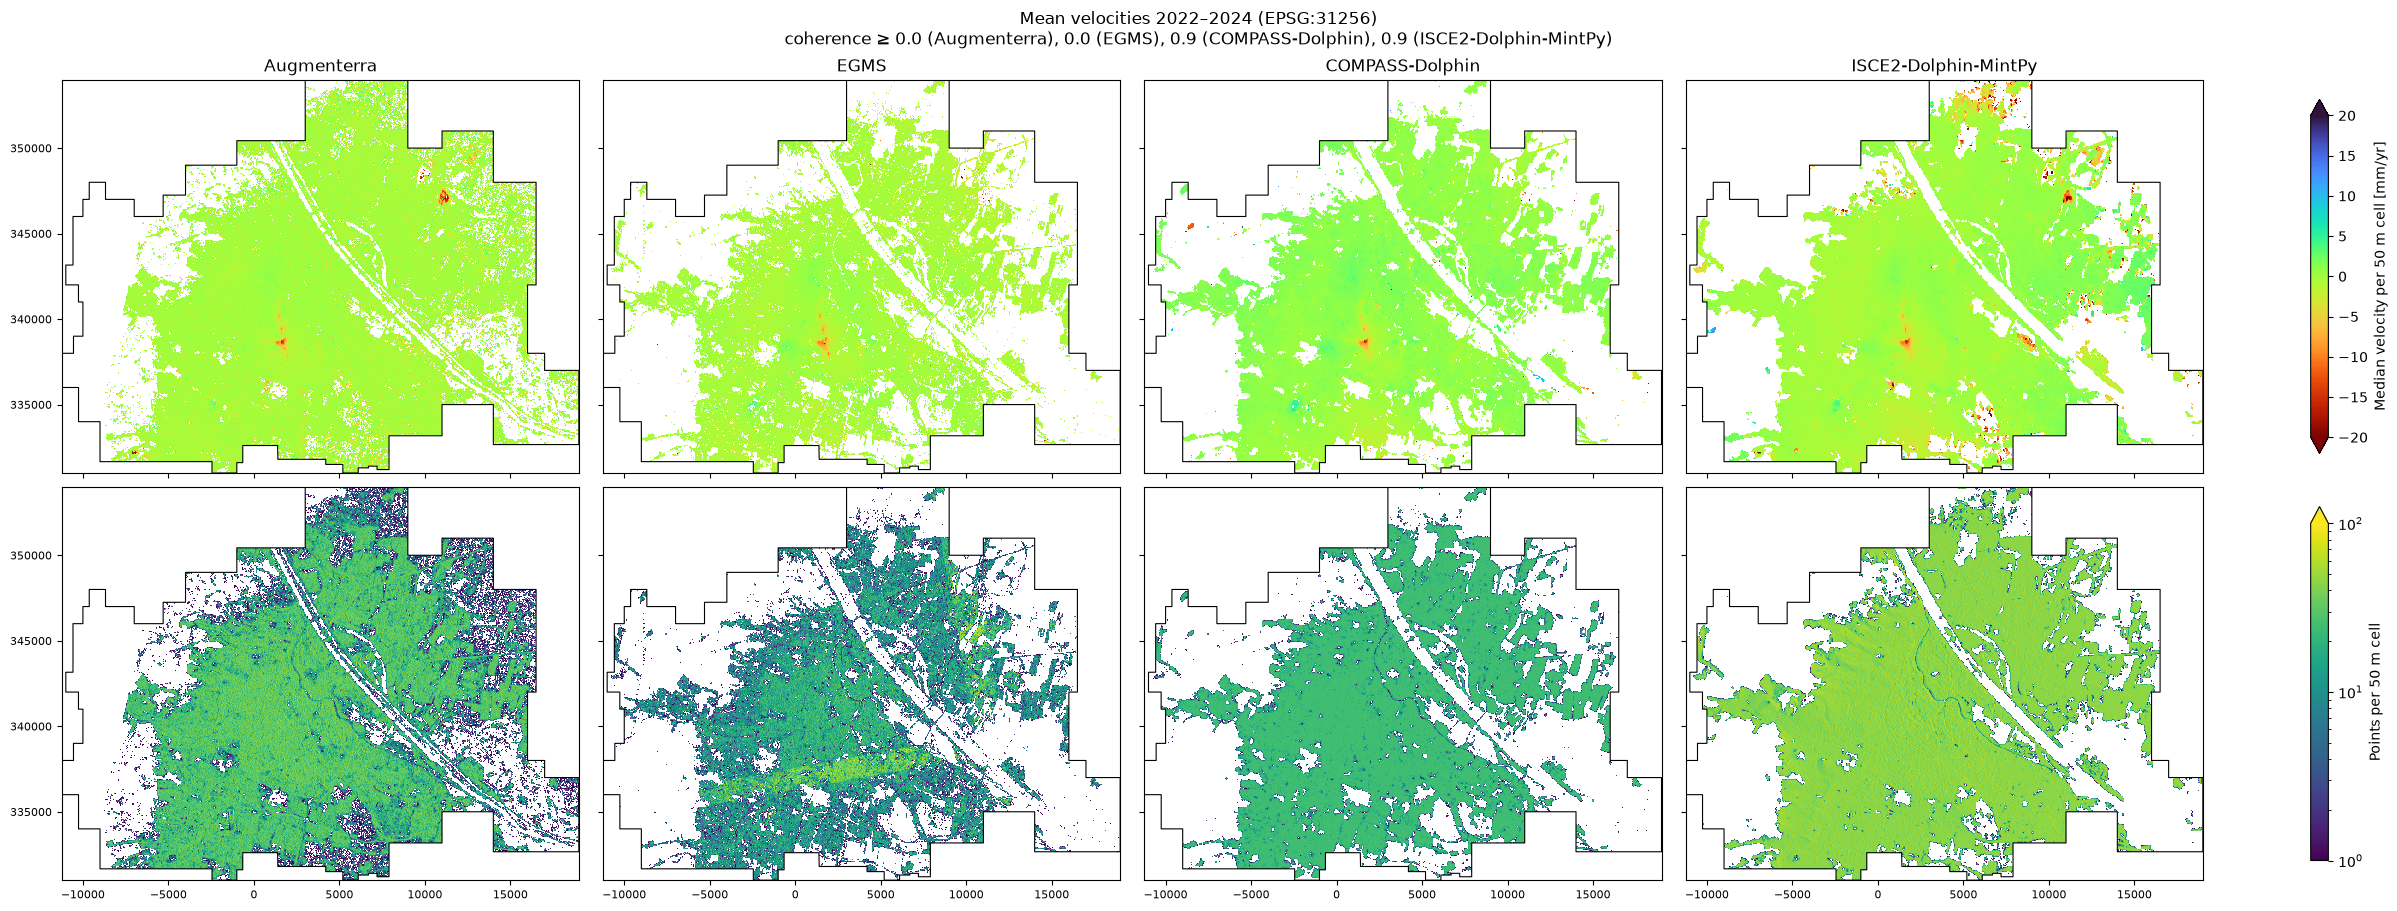

In [11]:
grid = spatial.Grid.over(aoi_metric, MAP_CELL_SIZE_M)
n = len(points)
fig, axes = plt.subplots(2, n, figsize=(6 * n, 9), sharex=True, sharey=True, constrained_layout=True)
axes = np.atleast_2d(axes.T).T      # keeps 2D indexing when only one dataset is configured

vel_norm = Normalize(-VEL_LIMIT, VEL_LIMIT)
count_norm = LogNorm(1, 100)

for col, (name, pts) in enumerate(points.items()):
    cells = grid.aggregate(pts, median=("velocity", "median"), count=("velocity", "size"))
    axes[0, col].imshow(grid.to_image(cells["median"]), extent=grid.extent, cmap=CMAP, norm=vel_norm,
                        interpolation="nearest")
    axes[1, col].imshow(grid.to_image(cells["count"]), extent=grid.extent, cmap="viridis", norm=count_norm,
                        interpolation="nearest")
    axes[0, col].set_title(name)
    for ax in axes[:, col]:
        style_map(ax, aoi_metric)

fig.colorbar(ScalarMappable(vel_norm, CMAP), ax=axes[0], extend="both", shrink=0.9,
             label=f"Median velocity per {MAP_CELL_SIZE_M} m cell [mm/yr]")
fig.colorbar(ScalarMappable(count_norm, "viridis"), ax=axes[1], extend="max", shrink=0.9,
             label=f"Points per {MAP_CELL_SIZE_M} m cell")
fig.suptitle(f"Mean velocities 2022–2024 ({METRIC_CRS})\n{COH_INFO}")
plt.show()

## 4. Comparison of velocities in test polygons

The polygons are evaluated on the AOI points loaded above (no further file access),
so polygons outside the AOI contain no points. The coherence filter from the configuration applies.

In [12]:
polygons = gpd.read_file(POLYGON_FILE).to_crs("EPSG:4326")
polygons_metric = polygons.to_crs(METRIC_CRS)


def points_in(pts, polygon):
    """Rows of an already loaded point table that lie inside `polygon` (EPSG:4326)."""
    return pts[spatial.inside(pts["lon"].to_numpy(), pts["lat"].to_numpy(), polygon)]

### 4.1 Overview of all polygons

One row per polygon; velocities in mm/yr.

In [13]:
POLYGON_COLUMNS = ["points", "mean", "median", "IQR"]
polygon_table = pd.concat({
    name: pd.DataFrame([metrics.velocity_summary(points_in(pts, poly)["velocity"])[POLYGON_COLUMNS]
                        for poly in polygons.geometry], index=polygons.index)
    for name, pts in points.items()
}, axis=1)
polygon_table.insert(0, ("polygon", "area [m²]"), polygons_metric.area)
polygon_table.index.name = "polygon index"
show(polygon_table, decimals=2, int_labels=("points", "area [m²]"))

### 4.2 Selected polygon in detail

Change `POLYGON_INDEX` and re-run the cells below.

In [14]:
POLYGON_INDEX = 0

polygon = polygons.geometry.iloc[POLYGON_INDEX]
polygon_metric = polygons_metric.geometry.iloc[POLYGON_INDEX]
selected = {name: points_in(pts, polygon) for name, pts in points.items()}

print(f"Polygon {POLYGON_INDEX}: area {polygon_metric.area:,.0f} m²")
for name, pts in selected.items():
    print(f"  {name:22s} {len(pts):>7,} points")

Polygon 0: area 14,220 m²
  Augmenterra                183 points
  EGMS                        32 points
  COMPASS-Dolphin            118 points
  ISCE2-Dolphin-MintPy       259 points


Points inside the polygon, one panel per dataset with the same colour scale.

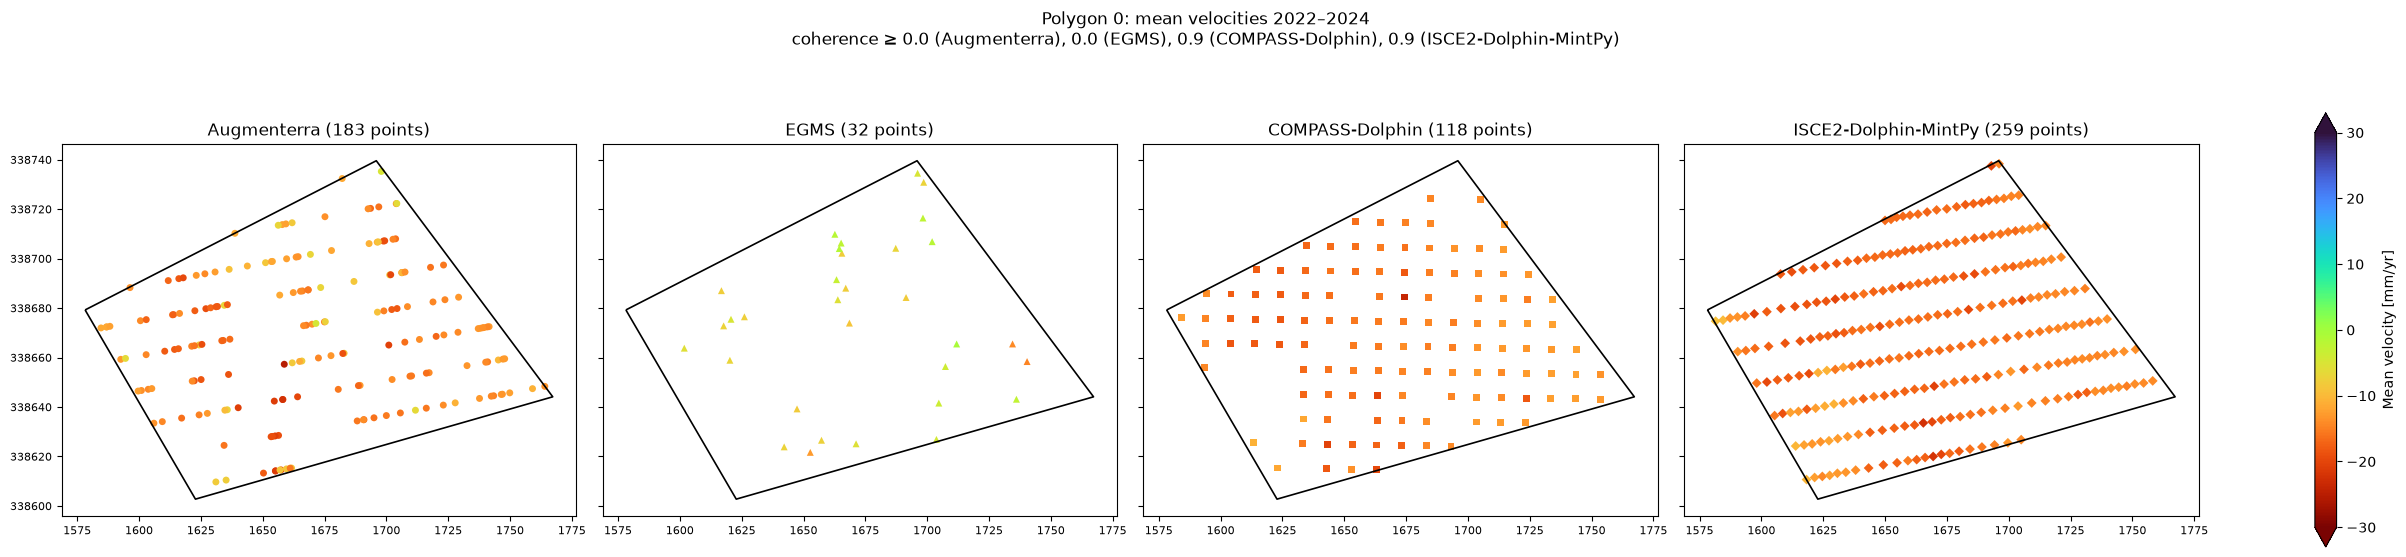

In [15]:
POLY_VEL_LIMIT = 30           # colour range for the polygon maps [mm/yr]
MARKER_SIZE = 25

poly_norm = Normalize(-POLY_VEL_LIMIT, POLY_VEL_LIMIT)
fig, axes = plt.subplots(1, n, figsize=(6 * n, 6), sharex=True, sharey=True, constrained_layout=True)
axes = np.atleast_1d(axes)

for ax, (name, pts) in zip(axes, selected.items()):
    gpd.GeoSeries([polygon_metric]).boundary.plot(ax=ax, color="black", lw=1.2)
    ax.scatter(pts["x"], pts["y"], c=pts["velocity"], cmap=CMAP, norm=poly_norm,
               s=MARKER_SIZE, marker=SOURCES[name].marker, edgecolors="none")
    ax.set_title(f"{name} ({len(pts):,} points)")
    ax.set_aspect("equal")
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=8)

fig.colorbar(ScalarMappable(poly_norm, CMAP), ax=axes, extend="both", shrink=0.8, label="Mean velocity [mm/yr]")
fig.suptitle(f"Polygon {POLYGON_INDEX}: mean velocities 2022–2024\n{COH_INFO}")
plt.show()

Velocity statistics in the polygon, and the differences `own − other` of each own processing to each reference
and of the two own processings to each other (`DIFF_PAIRS`; positive = the first dataset shows higher velocities,
i.e. less subsidence).

In [16]:
polygon_stats = pd.DataFrame({name: metrics.velocity_summary(pts["velocity"]) for name, pts in selected.items()})
show(polygon_stats)

differences = pd.DataFrame({
    f"{own} − {other}": polygon_stats[own] - polygon_stats[other]
    for own, other in DIFF_PAIRS if own in polygon_stats and other in polygon_stats
}).loc[["mean", "median", "P25", "P75", "IQR"]]
print("Differences [mm/yr]:")
show(differences)

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
points,183,32,118,259
mean,-14.09,-6.10,-15.18,-16.02
std,3.76,3.44,2.10,2.06
min,-25.30,-14.60,-23.73,-22.29
P2,-20.84,-14.29,-19.88,-20.07
P25,-16.70,-7.83,-16.55,-17.28
median,-14.10,-6.30,-15.02,-16.33
P75,-12.15,-3.55,-13.55,-14.58
P98,-6.43,-1.26,-11.98,-11.00
max,-4.60,-0.70,-11.01,-9.23


Differences [mm/yr]:


,COMPASS-Dolphin − Augmenterra,COMPASS-Dolphin − EGMS,ISCE2-Dolphin-MintPy − Augmenterra,ISCE2-Dolphin-MintPy − EGMS,ISCE2-Dolphin-MintPy − COMPASS-Dolphin
mean,-1.09,-9.08,-1.93,-9.92,-0.84
median,-0.92,-8.72,-2.23,-10.03,-1.32
P25,0.15,-8.72,-0.58,-9.45,-0.73
P75,-1.40,-10.00,-2.43,-11.03,-1.03
IQR,-1.55,-1.28,-1.85,-1.57,-0.30


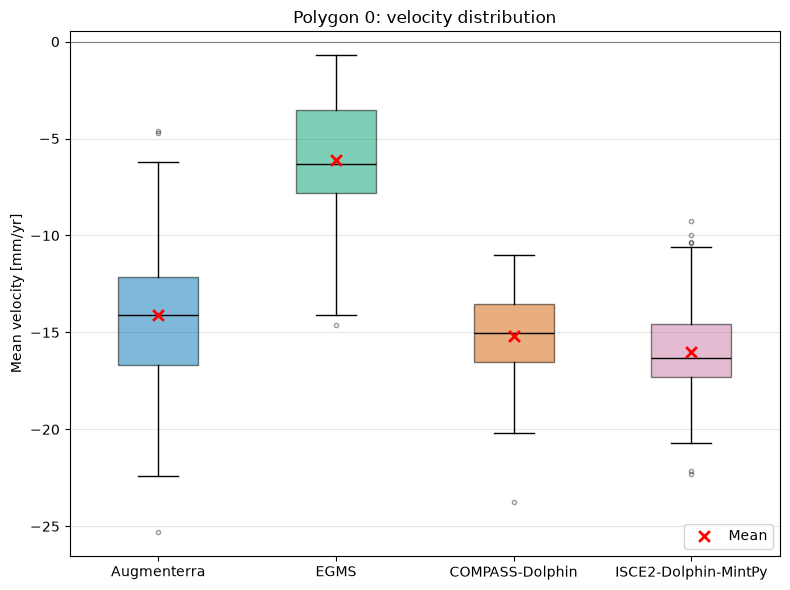

In [17]:
velocities = [pts["velocity"].dropna() for pts in selected.values()]
colors = [SOURCES[name].color for name in selected]

fig, ax = plt.subplots(figsize=(8, 6))
boxes = ax.boxplot(velocities, tick_labels=list(selected), showfliers=True, patch_artist=True,
                   medianprops=dict(color="black"), flierprops=dict(markersize=3, alpha=0.4))
for box, color in zip(boxes["boxes"], colors):
    box.set(facecolor=color, alpha=0.5)

ax.scatter(range(1, len(velocities) + 1), [v.mean() for v in velocities],
           marker="x", color="red", s=60, linewidths=2, zorder=3, label="Mean")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylabel("Mean velocity [mm/yr]")
ax.set_title(f"Polygon {POLYGON_INDEX}: velocity distribution")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Time series in the selected polygon

`readers.read_timeseries` reads only the row groups that contain the polygon points and only the
time-series columns between `TS_START` and `TS_END`. The result has the same layout for every dataset:
one row per point, one column per acquisition date (DatetimeIndex).

In [18]:
t0 = time.perf_counter()
timeseries = {name: readers.read_timeseries(SOURCES[name], pts, TS_START, TS_END) for name, pts in selected.items()}
print(f"Time series loaded in {time.perf_counter() - t0:.1f} s")

Time series loaded in 0.5 s


### 5.1 Time series overview and reference dates

A date at which all points have the value 0 is the reference date of the time series.

In [19]:
display(pd.DataFrame({name: tsa.overview(ts) for name, ts in timeseries.items()}))

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
points,183,32,118,259
time steps,343,209,92,92
first date,2019-01-05,2020-01-06,2022-01-01,2022-01-01
last date,2026-04-28,2024-12-28,2024-12-28,2024-12-28
median spacing [days],6.0,6.0,12.0,12.0
reference date (all values 0),2019-01-05,none,2022-01-01,2022-03-02


**Reference of each dataset**
* **Augmenterra**: first acquisition of the analysis (2019-01-05).
* **EGMS**: no zero date; EGMS uses a virtual temporal reference based on a model of the time series:

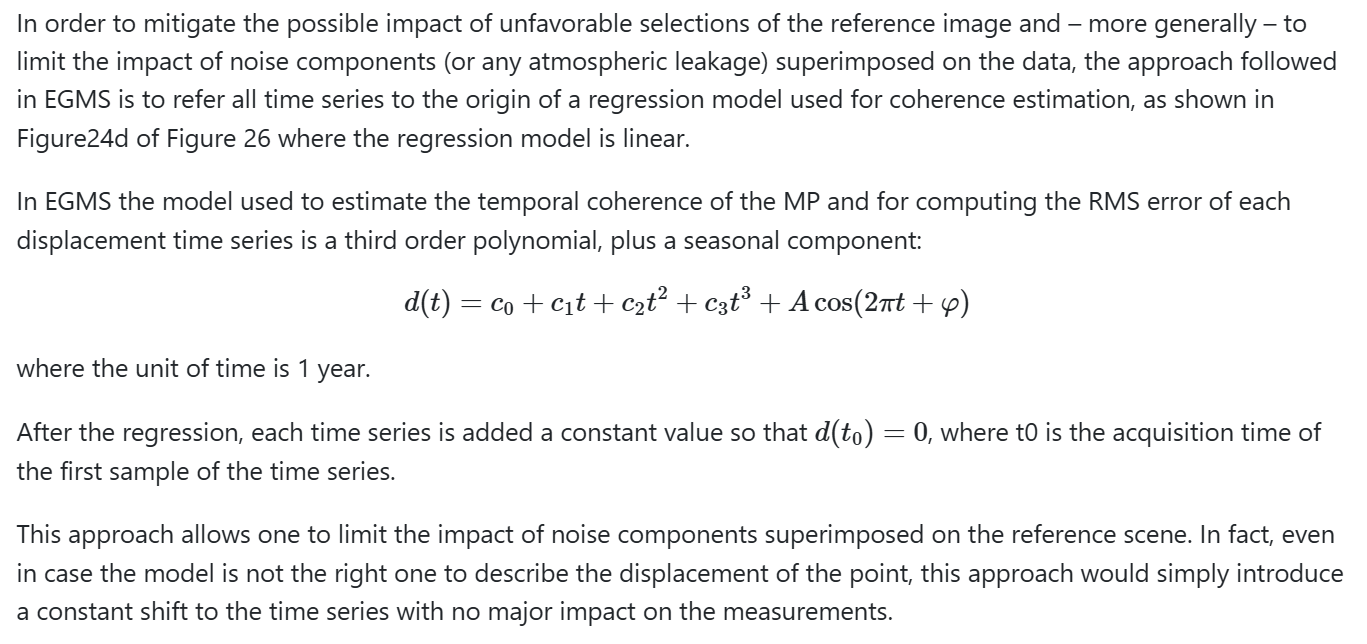

* **COMPASS-Dolphin**: first acquisition of the stack (see table above).
* **ISCE2-Dolphin-MintPy**: MintPy reference date 2022-03-02 (from the `.metadata.json`; see table above),
  spatial reference point at 16.3254 E / 48.1976 N.

### 5.2 Original time series

Thin lines: individual points (random sample of at most `MAX_TS_LINES`).
Thick line: median of all points; band: interquartile range (P25–P75).
The offsets between the panels come from the different reference dates.

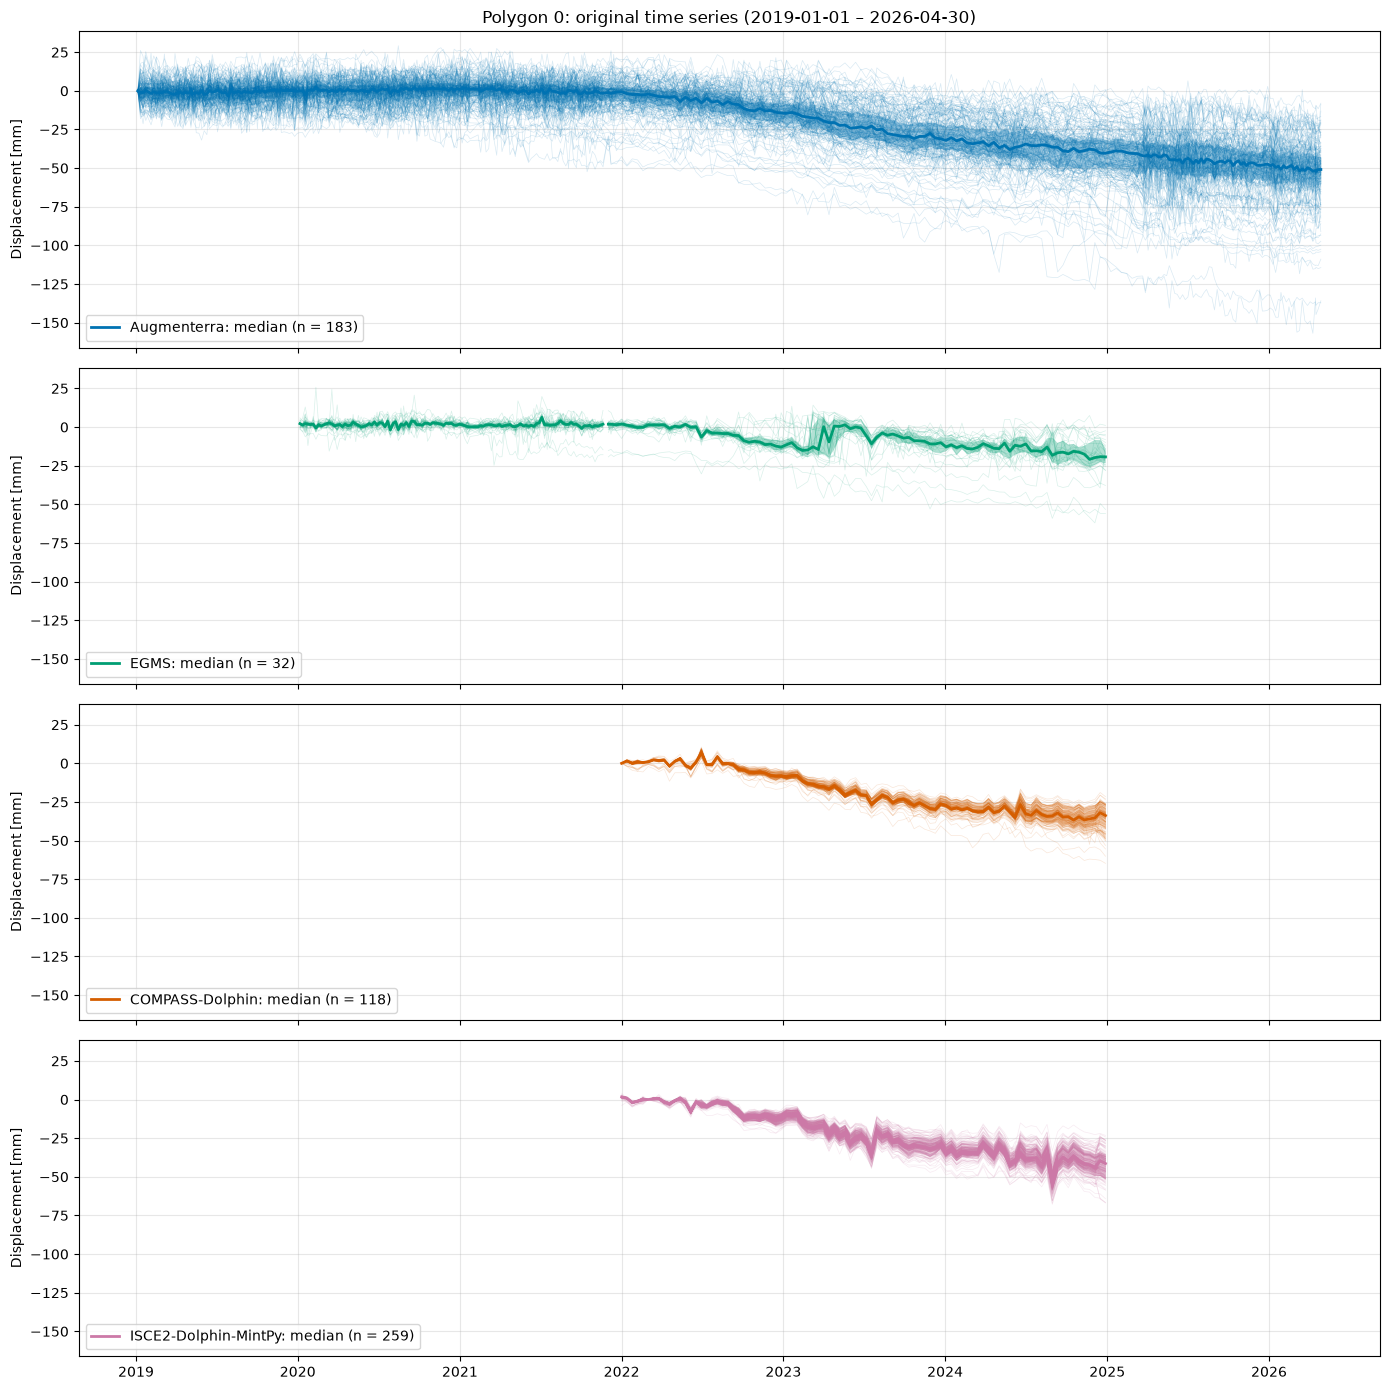

In [20]:
fig, axes = plt.subplots(n, 1, figsize=(14, 3.5 * n), sharex=True, sharey=True)
axes = np.atleast_1d(axes)
for ax, (name, ts) in zip(axes, timeseries.items()):
    plot_ts_band(ax, ts, SOURCES[name].color, name, max_lines=MAX_TS_LINES)
    ax.set_ylabel("Displacement [mm]")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left")
axes[0].set_title(f"Polygon {POLYGON_INDEX}: original time series ({TS_START.date()} – {TS_END.date()})")
plt.tight_layout()
plt.show()

### 5.3 Re-referencing to a common date

Each point's time series is shifted so that it is 0 at the first acquisition date shared by all datasets.

In [21]:
common = tsa.common_dates(timeseries)
REFERENCE_DATE = common[0]        # can be replaced by any other date from `common`

print(f"Common acquisition dates: {len(common)} ({common[0].date()} – {common[-1].date()})")
print(f"Reference date: {REFERENCE_DATE.date()}")

timeseries_reref = {name: tsa.rereference(ts, REFERENCE_DATE) for name, ts in timeseries.items()}

Common acquisition dates: 92 (2022-01-01 – 2024-12-28)
Reference date: 2022-01-01


Top: median and P25–P75 band of the re-referenced time series.
Bottom: difference of the median time series `own − other` for every pair in `DIFF_PAIRS`, on the common dates
(colour = other dataset, solid / dashed = first / second own processing).

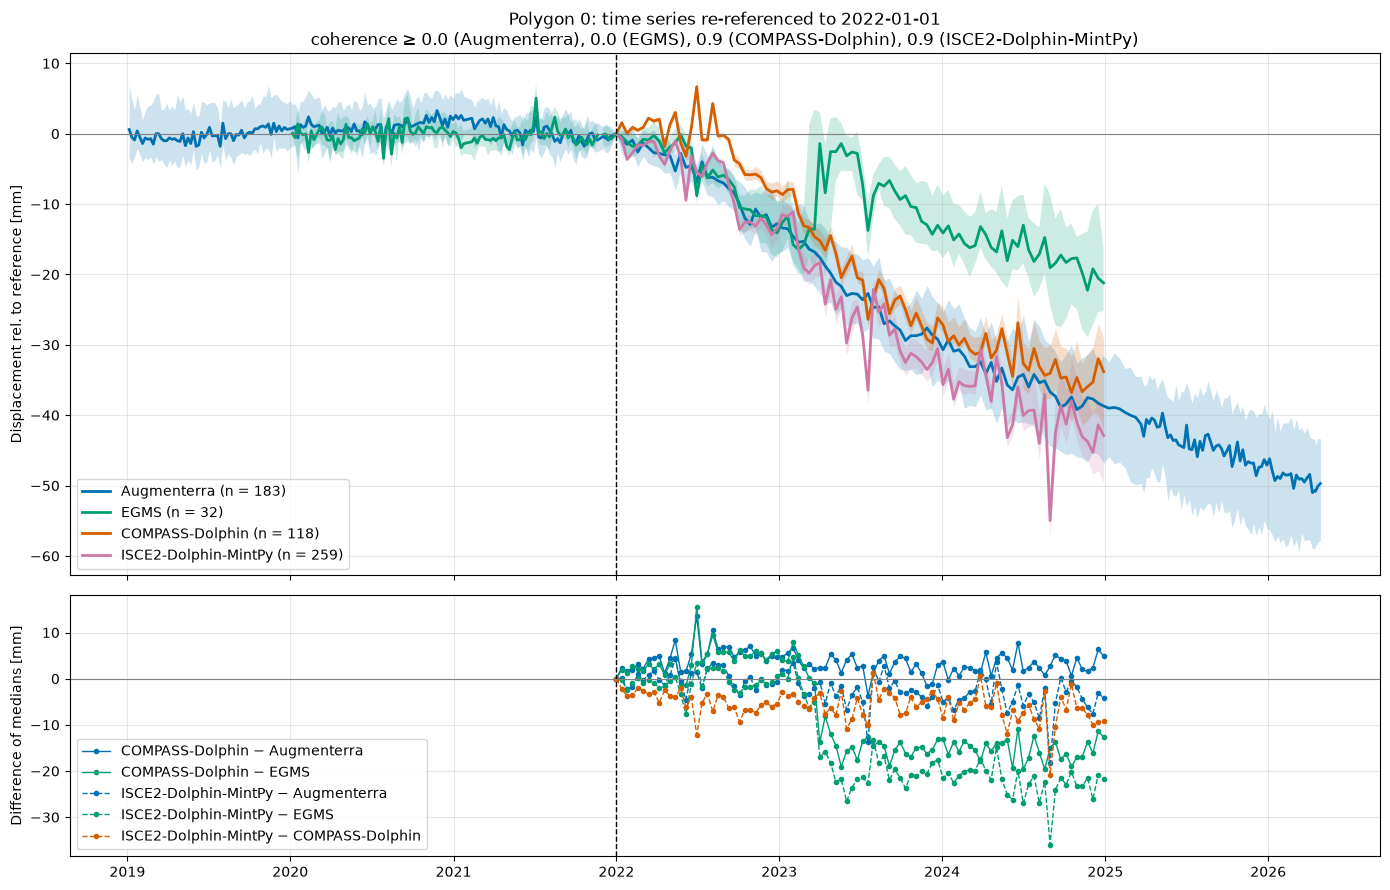

In [22]:
fig, (ax_ts, ax_diff) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

for name, ts in timeseries_reref.items():
    color = SOURCES[name].color
    q25, q50, q75 = ts.quantile([0.25, 0.5, 0.75]).to_numpy()
    ax_ts.fill_between(ts.columns, q25, q75, color=color, alpha=0.2, lw=0)
    ax_ts.plot(ts.columns, q50, color=color, lw=2, label=f"{name} (n = {len(ts):,})")

for own, other in DIFF_PAIRS:
    if own in timeseries_reref and other in timeseries_reref:
        diff = timeseries_reref[own][common].median() - timeseries_reref[other][common].median()
        ax_diff.plot(common, diff, color=SOURCES[other].color, ls="-" if own == OWN[0] else "--",
                     marker=".", lw=1, label=f"{own} − {other}")

for ax in (ax_ts, ax_diff):
    ax.axvline(REFERENCE_DATE, color="black", ls="--", lw=1)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left")
ax_ts.set_ylabel("Displacement rel. to reference [mm]")
ax_diff.set_ylabel("Difference of medians [mm]")
ax_ts.set_title(f"Polygon {POLYGON_INDEX}: time series re-referenced to {REFERENCE_DATE.date()}\n{COH_INFO}")
plt.tight_layout()
plt.show()

### 5.4 Consistency of velocities and time series

All values on the common dates. The trend is a linear fit to the median time series; it should be
close to the median of the velocity attribute if both describe the same period.

In [23]:
ts_summary = {}
for name, ts in timeseries_reref.items():
    median_series = ts[common].median()
    ts_summary[name] = {
        "points": len(ts),
        "median of velocity attribute [mm/yr]": selected[name]["velocity"].median(),
        "trend of median time series [mm/yr]": tsa.trend(median_series),
        f"median displacement on {common[-1].date()} [mm]": median_series.iloc[-1],
        "median P25–P75 spread over time [mm]": (ts[common].quantile(0.75) - ts[common].quantile(0.25)).median(),
    }
show(pd.DataFrame(ts_summary))

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
points,183,32,118,259
median of velocity attribute [mm/yr],-14.10,-6.30,-15.02,-16.33
trend of median time series [mm/yr],-14.36,-5.87,-15.01,-16.31
median displacement on 2024-12-28 [mm],-38.70,-21.20,-33.81,-42.90
median P25–P75 spread over time [mm],10.10,7.86,2.55,3.44
